# 04 - Bootstrap CIs + comparison figure

All methods on the same 148 out-of-fold predictions (seed-123 folds), with 95% bootstrap CIs
on accuracy and AUC. Baselines use the CORRECTED frozen features from notebook 00. Fine-tune
rows read `finetune_shared*.pt` from notebooks 02/03 (skipped with a message if not yet run).
Produces `results_sensor/bootstrap_comparison.png`.

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
DATA='../data'; OUT='../results_sensor'
labels=np.load(f'{DATA}/preprocessed/labels.npy'); N=len(labels)
cv=StratifiedKFold(5, shuffle=True, random_state=123)

## Pooled out-of-fold predictions. Each subject predicted once, by a model that never saw them.
def oof_lr(X):
    pred=np.zeros(N,int); prob=np.zeros(N)
    for tr,te in cv.split(X,labels):
        lr=LogisticRegression(max_iter=2000).fit(X[tr],labels[tr])
        pred[te]=lr.predict(X[te]); prob[te]=lr.predict_proba(X[te])[:,1]
    return pred,prob

M=[]
p,pr=oof_lr(np.load(f'{DATA}/baseline_features.npy')); M.append(('Handcrafted + LR','hand',p,pr))
p,pr=oof_lr(np.load(f'{OUT}/frozen_tiny.npy'));         M.append(('Frozen tiny + LR','froz',p,pr))
p,pr=oof_lr(np.load(f'{OUT}/frozen_base.npy'));         M.append(('Frozen base + LR','froz',p,pr))
for tag,fn in [('tiny','finetune_shared.pt'),('base','finetune_shared_base.pt')]:
    path=f'{OUT}/{fn}'
    if not os.path.exists(path):
        print(f'skip fine-tune {tag}: {fn} not found (run notebooks 02/03 first)'); continue
    c=torch.load(path, map_location='cpu', weights_only=False)['cv'][10]   # last-1 block
    M.append((f'Fine-tune {tag} + NN','ft',c['nn_pred'],c['nn_prob']))
    M.append((f'Fine-tune {tag} + LR','ft',c['lr_pred'],c['lr_prob']))
print('methods assembled:', len(M))

methods assembled: 7


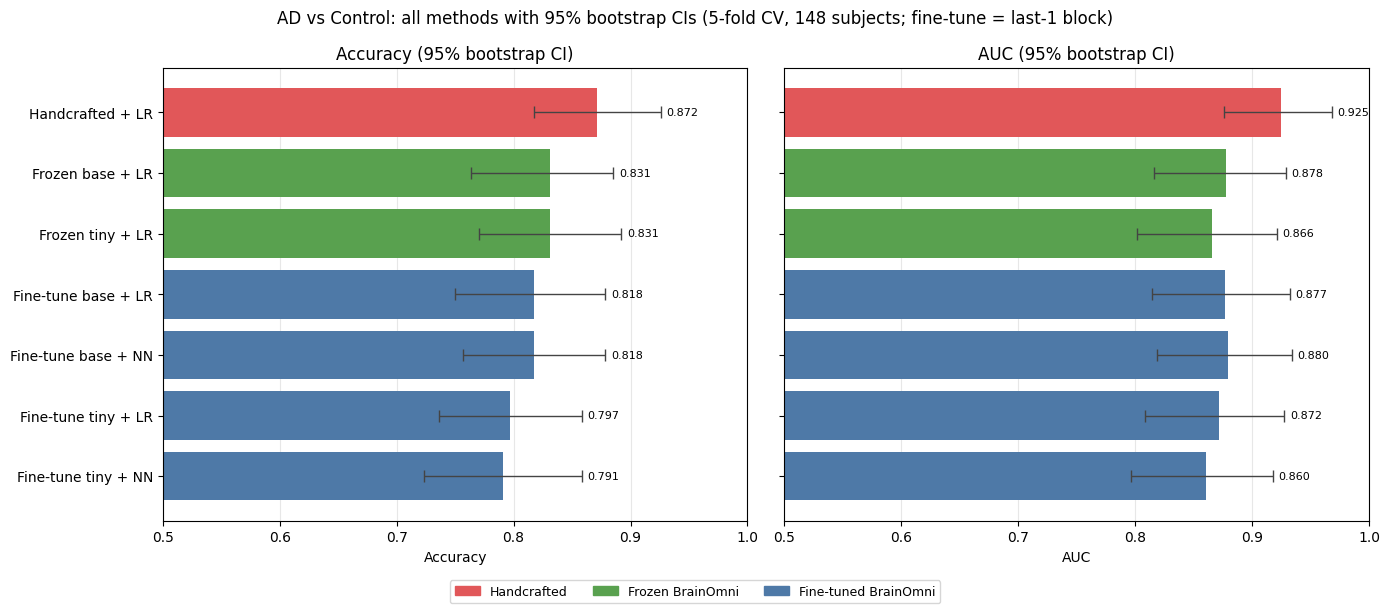

Saved bootstrap_comparison.png
  Fine-tune tiny + NN    acc 0.791 [0.723,0.858]  AUC 0.860 [0.797,0.917]
  Fine-tune tiny + LR    acc 0.797 [0.736,0.858]  AUC 0.872 [0.808,0.928]
  Fine-tune base + NN    acc 0.818 [0.757,0.878]  AUC 0.880 [0.819,0.934]
  Fine-tune base + LR    acc 0.818 [0.750,0.878]  AUC 0.877 [0.815,0.932]
  Frozen tiny + LR       acc 0.831 [0.770,0.892]  AUC 0.866 [0.802,0.921]
  Frozen base + LR       acc 0.831 [0.764,0.885]  AUC 0.878 [0.817,0.929]
  Handcrafted + LR       acc 0.872 [0.817,0.926]  AUC 0.925 [0.876,0.968]


In [4]:
def boot(a, metric, nb=2000, seed=123):
    rng=np.random.default_rng(seed); idx=np.arange(N); v=[]
    for _ in range(nb):
        b=rng.choice(idx,N,replace=True)
        try: v.append(metric(labels[b],a[b]))
        except ValueError: pass
    return metric(labels,a), *np.percentile(v,[2.5,97.5])

rows=[]
for name,grp,pred,prob in M:
    a,alo,ahi=boot(pred,accuracy_score); u,ulo,uhi=boot(prob,roc_auc_score)
    rows.append((name,grp,a,alo,ahi,u,ulo,uhi))
rows.sort(key=lambda r:r[2])
gcol={'hand':'#E15759','froz':'#59A14F','ft':'#4E79A7'}
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,6)); y=np.arange(len(rows))
acc=[r[2] for r in rows]; ael=[r[2]-r[3] for r in rows]; aeh=[r[4]-r[2] for r in rows]; cols=[gcol[r[1]] for r in rows]
ax1.barh(y,acc,xerr=[ael,aeh],capsize=4,color=cols,error_kw=dict(lw=1,ecolor='#444'))
for yi,r in zip(y,rows): ax1.text(r[4]+0.005,yi,f'{r[2]:.3f}',va='center',fontsize=8)
ax1.set_yticks(y); ax1.set_yticklabels([r[0] for r in rows]); ax1.set_xlim(0.5,1.0)
ax1.set_xlabel('Accuracy'); ax1.set_title('Accuracy (95% bootstrap CI)'); ax1.grid(axis='x',alpha=0.3); ax1.set_axisbelow(True)
auc=[r[5] for r in rows]; uel=[r[5]-r[6] for r in rows]; ueh=[r[7]-r[5] for r in rows]
ax2.barh(y,auc,xerr=[uel,ueh],capsize=4,color=cols,error_kw=dict(lw=1,ecolor='#444'))
for yi,r in zip(y,rows): ax2.text(r[7]+0.005,yi,f'{r[5]:.3f}',va='center',fontsize=8)
ax2.set_yticks(y); ax2.set_yticklabels([]); ax2.set_xlim(0.5,1.0)
ax2.set_xlabel('AUC'); ax2.set_title('AUC (95% bootstrap CI)'); ax2.grid(axis='x',alpha=0.3); ax2.set_axisbelow(True)
fig.legend(handles=[Patch(color='#E15759',label='Handcrafted'),Patch(color='#59A14F',label='Frozen BrainOmni'),
                    Patch(color='#4E79A7',label='Fine-tuned BrainOmni')],fontsize=9,loc='lower center',ncol=3,bbox_to_anchor=(0.5,-0.02))
fig.suptitle('AD vs Control: all methods with 95% bootstrap CIs (5-fold CV, 148 subjects; fine-tune = last-1 block)',fontsize=12)
plt.tight_layout(rect=[0,0.03,1,1]); plt.savefig(f'{OUT}/bootstrap_comparison.png',dpi=150,bbox_inches='tight'); plt.show()
print('Saved bootstrap_comparison.png')
for r in rows: print(f'  {r[0]:22s} acc {r[2]:.3f} [{r[3]:.3f},{r[4]:.3f}]  AUC {r[5]:.3f} [{r[6]:.3f},{r[7]:.3f}]')

## Paired differences vs the handcrafted baseline

Overlapping confidence intervals are a *weak* argument for "no difference": two 95% CIs can overlap
while the paired difference still excludes zero. The rigorous test is to bootstrap the
**difference** directly, on the same resamples, so the comparison is paired (both methods see the
same resampled subjects each iteration). An interval containing 0 means the methods are not
statistically distinguishable.

The pairing also matters for power: because all methods are evaluated on identical subjects, their
errors are correlated, and the paired interval is tighter than what you would get by comparing two
independent intervals.

In [5]:
# Paired bootstrap: difference vs handcrafted, same resamples for both methods, ALL depths
def boot_diff(pred_a, pred_b, metric, nb=2000, seed=123):
    """metric(a) - metric(b), bootstrapped on identical resamples (paired)."""
    rng = np.random.default_rng(seed); idx = np.arange(N); diffs = []
    for _ in range(nb):
        b = rng.choice(idx, N, replace=True)
        try:
            diffs.append(metric(labels[b], pred_a[b]) - metric(labels[b], pred_b[b]))
        except ValueError:
            pass
    point = metric(labels, pred_a) - metric(labels, pred_b)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return point, lo, hi

# Reference = handcrafted
ref_pred, ref_prob = oof_lr(np.load(f'{DATA}/baseline_features.npy'))

# Assemble every method: frozen (2) + fine-tuned (2 models x 3 depths x 2 heads = 12)
DEPTH_NAME = {10: 'last-1 block', 9: 'last-2 blocks', 8: 'last-3 blocks'}
METHODS = []
for tag, fn in [('base', 'frozen_base.npy'), ('tiny', 'frozen_tiny.npy')]:
    p, pr = oof_lr(np.load(f'{OUT}/{fn}'))
    METHODS.append(('Frozen', f'{tag} + LR', p, pr))
for nf in [10, 9, 8]:
    for tag, sfx in [('base', '_base'), ('tiny', '')]:
        path = f'{OUT}/finetune_shared{sfx}.pt'
        if not os.path.exists(path):
            continue
        c = torch.load(path, map_location='cpu', weights_only=False)['cv'][nf]
        grp = f'Fine-tuned, {DEPTH_NAME[nf]}'
        METHODS.append((grp, f'{tag} + NN', c['nn_pred'], c['nn_prob']))
        METHODS.append((grp, f'{tag} + LR', c['lr_pred'], c['lr_prob']))
print(f'{len(METHODS)} methods vs handcrafted reference\n')

rows = []
print(f'{"group":28s} {"method":12s} {"D acc [95% CI]":>26} {"D AUC [95% CI]":>26}  sig?')
for grp, name, pred, prob in METHODS:
    da, dalo, dahi = boot_diff(pred, ref_pred, accuracy_score)
    du, dulo, duhi = boot_diff(prob, ref_prob, roc_auc_score)
    sig = 'YES' if (dalo > 0 or dahi < 0) else 'no'
    rows.append((grp, name, da, dalo, dahi, du, dulo, duhi, sig))
    print(f'{grp:28s} {name:12s} {da:+.3f} [{dalo:+.3f}, {dahi:+.3f}] '
          f'{du:+.3f} [{dulo:+.3f}, {duhi:+.3f}]  {sig}')

n_sig = sum(1 for r in rows if r[8] == 'YES')
print(f'\n{n_sig} of {len(rows)} methods differ significantly from handcrafted (accuracy).')
if n_sig == 0:
    print('-> every interval contains zero: all methods statistically tied with handcrafted.')

# LaTeX rows, grouped, ready to paste into the tabular
print('\n--- LaTeX ---')
last_grp = None
for grp, name, da, dalo, dahi, du, dulo, duhi, sig in rows:
    if grp != last_grp:
        print(f'\\multicolumn{{3}}{{|l|}}{{\\textit{{{grp}}}}} \\\\')
        print('\\hline')
        last_grp = grp
    print(f'\\quad {name} & ${da:+.3f}$ [${dalo:+.3f}$, ${dahi:+.3f}$] '
          f'& ${du:+.3f}$ [${dulo:+.3f}$, ${duhi:+.3f}$] \\\\')
    print('\\hline')

14 methods vs handcrafted reference

group                        method                   D acc [95% CI]             D AUC [95% CI]  sig?
Frozen                       base + LR    -0.041 [-0.108, +0.027] -0.047 [-0.096, -0.001]  no
Frozen                       tiny + LR    -0.041 [-0.108, +0.027] -0.059 [-0.113, -0.008]  no
Fine-tuned, last-1 block     base + NN    -0.054 [-0.122, +0.020] -0.045 [-0.091, +0.001]  no
Fine-tuned, last-1 block     base + LR    -0.054 [-0.122, +0.014] -0.047 [-0.095, -0.001]  no
Fine-tuned, last-1 block     tiny + NN    -0.081 [-0.149, -0.007] -0.064 [-0.113, -0.014]  YES
Fine-tuned, last-1 block     tiny + LR    -0.074 [-0.142, -0.007] -0.053 [-0.100, -0.006]  YES
Fine-tuned, last-2 blocks    base + NN    -0.054 [-0.128, +0.027] -0.053 [-0.106, -0.003]  no
Fine-tuned, last-2 blocks    base + LR    -0.054 [-0.122, +0.020] -0.050 [-0.100, -0.002]  no
Fine-tuned, last-2 blocks    tiny + NN    -0.088 [-0.162, -0.014] -0.066 [-0.115, -0.016]  YES
Fine-tuned, 